# Few-Shot Ordinal-Aware CLIP for Diabetic Retinopathy Grading
## DeepDRiD Benchmark — Full Training & Evaluation Notebook

This notebook provides a **complete, reproducible pipeline** for the few-shot ordinal DR grading paper:

| Step | Description |
|------|-------------|
| **1** | Environment setup & imports |
| **2** | Experiment grid definition |
| **3** | Dataset overview & class distribution plots |
| **4** | Prepare few-shot splits |
| **5** | Train all experiments (modality × k-shot × seed) |
| **6** | Parse & aggregate results |
| **7** | Paper-quality plots: k-shot curves, confusion matrices, ablation table |

---
**Modalities**: CFP · OCT · UWF  
**k-shots**: 0 (zero-shot), 1, 2, 4, 8, 16, 32  
**Seeds**: 1 · 2 · 3 · 4 · 5  
**Metrics**: QWK · MAE · Macro-F1 · AUC · Accuracy · LOS

## 1 · Environment Setup

In [11]:
import os, sys, json, warnings, logging
import subprocess
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import pytorch_lightning as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from omegaconf import OmegaConf
from tqdm import tqdm
import sys
# import tqdm.std
# sys.modules['tqdm.notebook'] = tqdm.std  # Tricks PyTorch Lightning into using standard tqdm

warnings.filterwarnings('ignore')
logging.getLogger('pytorch_lightning').setLevel(logging.ERROR)

# ── Locate project root (contains 'configs/' dir) ────────────────────────────
ROOT = Path.cwd()
while not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from scripts.train import load_config
from src.data.datamodule import FewShotDataModule
from src.models.runner import FewShotOrdinalRunner

RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project root : {ROOT}')
print(f'Device       : {DEVICE}')
print(f'Results dir  : {RESULTS}')
print(f'PyTorch      : {torch.__version__}')
print(f'PL           : {pl.__version__}')

Project root : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace
Device       : cuda
Results dir  : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results
PyTorch      : 2.8.0+cu126
PL           : 2.6.5


## 1b · Auto-generate DeepDRiD Manifest

Converts raw DeepDRiD CSV files into the standardised `CFP_manifest.csv`.
Safe to re-run; silently skipped if manifest already exists.


In [12]:
# Auto-generate the DeepDRiD manifest if it does not yet exist.
import subprocess as _sp
_manifest = ROOT / 'data/DeepDRiD' / 'CFP_manifest.csv'
if not _manifest.exists():
    print(f'Generating DeepDRiD manifest -> {_manifest}')
    r = _sp.run(
        [sys.executable, 'scripts/prepare_external_datasets.py', '--skip-aptos'],
        capture_output=True, text=True,
    )
    print(r.stdout)
    if r.returncode != 0:
        print('ERROR:', r.stderr)
else:
    print(f'Manifest OK: {_manifest} ({len(pd.read_csv(_manifest)):,} rows)')


Manifest OK: d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\data\DeepDRiD\CFP_manifest.csv (1,600 rows)


## 2 · Experiment Grid

Edit these cells to control what gets trained / re-run.

# Configuration Options Reference

This table outlines all the available configuration overrides in the MMRDR framework. These keys can be passed to the `load_config(overrides=[...])` function to dynamically alter the model architecture, data loading, or training pipeline.

| Configuration Key | Type | Available Options / Examples | Description |
| :--- | :--- | :--- | :--- |
| **`runner`** | String | `"src.models.runner.FewShotOrdinalRunner"`, <br>`"src.models.runner.StandardRunner"` | The PyTorch Lightning module used to run the training/inference loop. |
| **`model.image_encoder.name`** | String | `"RN50"`, `"RN101"`, `"ViT-B/32"`, `"ViT-B/16"`, `"ViT-L/14"` | The backbone architecture for the vision encoder. |
| **`model.image_encoder.lora.enabled`** | Boolean | `true`, `false` | Toggles Low-Rank Adaptation (LoRA) on the image encoder for parameter-efficient fine-tuning. |
| **`model.image_encoder.lora.r`** | Integer | `2`, `4`, `8`, `16`, `32`, `64` | The rank (`r`) dimension used for LoRA projection matrices. |
| **`model.text_encoder.name`** | String | `"RN50"`, `"ViT-B/32"`, etc. | The backbone for the text encoder (usually tied to the selected CLIP image encoder). |
| **`model.prompt_learner.name`** | String | `"rankformer_prompt_learner"`, <br>`"ordinalclip_rank_prompt_learner"`, <br>`"DR_prompt_learner"` | The prompt learning strategy. Use `ordinalclip_rank_prompt_learner` to disable RankFormer and simulate the baseline. |
| **`model.prompt_learner.num_ranks`** | Integer | `3`, `4`, `5` | The number of ordinal classes/grades (e.g., 5 for Diabetic Retinopathy). |
| **`model.prompt_learner.num_tokens_for_context`**| Integer | `4`, `8`, `16`, `32` | Number of learnable context tokens prepended to the prompt. |
| **`model.prompt_learner.attn_heads`** | Integer | `1`, `2`, `4`, `8` | Number of attention heads used if using the RankFormer prompt learner. |
| **`model.sms.enabled`** | Boolean | `true`, `false` | Toggles the Similarity Matrix Smoothing (SMS) calibration module. |
| **`data.modality`** | String | `"CFP"`, `"OCT"`, `"UWF"`, `"ALL"` | The imaging modality to load. |
| **`data.k_shot`** | Integer | `1`, `2`, `4`, `8`, `16`, `32`, `100` | The number of examples per class to use in the support (training) set. |
| **`data.seed`** | Integer | `1`, `42`, `1234`, etc. | Random seed for reproducibility (especially for few-shot sampling). |
| **`data.batch_query`** | Integer | `8`, `16`, `32`, `64`, `128` | Batch size used for validation and testing sets. |
| **`data.image_size`** | Integer | `224`, `336`, `384` | Input resolution to resize images to before passing them into the model. |
| **`data.manifest`** | String | `"data/MMRDR/CFP_manifest.csv"`, etc. | Path to the CSV manifest containing image paths and labels. |
| **`data.splits_dir`** | String | `"data/MMRDR/splits"`, etc. | Directory where train/val/test split indices are stored. |
| **`data.num_workers`** | Integer | `0`, `2`, `4`, `8` | Number of CPU workers for the PyTorch DataLoader (use `0` on Windows if facing multiprocessing crashes). |
| **`loss.lambda_rank`** | Float | `0.0`, `0.5`, `1.0`, `2.0` | Weight for the ordinal ranking loss component. Set to `0.0` to disable. |
| **`loss.mu_pairwise`** | Float | `0.0`, `0.1`, `0.5`, `1.0` | Weight for the pairwise margin loss component. Set to `0.0` to disable. |
| **`loss.tau`** | Float | `0.07`, `0.1`, `1.0` | Temperature scaling parameter used in the contrastive loss function. |
| **`train.epochs`** | Integer | `50`, `100`, `200` | Maximum number of training epochs (typically small for few-shot learning). |
| **`train.optimizer`** | String | `"adamw"`, `"adam"`, `"sgd"` | The optimization algorithm to use. |
| **`train.lr`** | Float | `1e-5`, `5e-5`, `1e-4`, `1e-3` | The peak learning rate. |
| **`train.weight_decay`** | Float | `0.0`, `1e-4`, `1e-2` | L2 weight decay regularization factor. |
| **`train.scheduler`** | String | `"cosine"`, `"step"`, `"linear"`, `"none"` | Learning rate scheduler type. |
| **`train.warmup_epochs`** | Integer | `0`, `5`, `10` | Number of epochs to linearly warm up the learning rate. |
| **`train.early_stopping_patience`**| Integer | `10`, `20`, `50` | Number of epochs with no improvement before stopping training early. |
| **`train.early_stopping_monitor`** | String | `"val_qwk"`, `"val_acc"`, `"val_loss"` | The validation metric to monitor for early stopping. |
| **`train.early_stopping_mode`** | String | `"max"`, `"min"` | Whether the monitored metric should be maximized (`max`) or minimized (`min`). |
| **`metrics`** | List[String] | `["qwk", "mae", "macro_f1", "auc", "acc", "los"]` | Subset of evaluation metrics to calculate and log during validation/testing. |


In [13]:
# ── Modality → config file + number of DR grades ─────────────────────────────
MODALITIES = {
    'CFP': {'config': 'configs/deepdrid_cfp.yaml', 'num_ranks': 5},
}
DATASET = 'DeepDRiD'  # used for labelling

# ── k-shot regimes (0 = zero-shot, no training) ───────────────────────────────
K_SHOTS = [0, 1, 2, 4, 8, 16, 24, 32]

# ── Seeds for statistical reliability ────────────────────────────────────────
SEEDS = [1, 2, 3, 4, 5]

# ── Per-run epoch budget (100 is appropriate for few-shot) ───────────────────
EPOCHS = 50

# ── Ablation variants (empty dict = full model) ───────────────────────────────
ABLATIONS = {
    'Ours (Full)':         {},
    #'w/o RankFormer':      {'model.prompt_learner.name': 'ordinalclip_rank_prompt_learner'},
    'w/o SMS':             {'model.sms.enabled': 'false'},
    #'w/o PairwiseLoss':    {'loss.mu_pairwise': '0.0'},
    'w/o RankingLoss':     {'loss.lambda_rank': '0.0'},
    #'w/o LoRA':            {'model.image_encoder.lora.enabled': 'false'},
}

# ── Quick count ───────────────────────────────────────────────────────────────
fs_k   = [k for k in K_SHOTS if k > 0]
zs_runs = len(MODALITIES)
fs_runs = len(MODALITIES) * len(fs_k) * len(SEEDS)
print(f'Modalities  : {list(MODALITIES)}')
print(f'k-shots     : {K_SHOTS}  (0 = zero-shot)')
print(f'Seeds       : {SEEDS}')
print(f'Zero-shot   : {zs_runs} run(s)')
print(f'Few-shot    : {fs_runs} runs  (× {len(ABLATIONS)} variants = {fs_runs * len(ABLATIONS)} for full ablation)')

Modalities  : ['CFP']
k-shots     : [0, 1, 2, 4, 8, 16, 24, 32]  (0 = zero-shot)
Seeds       : [1, 2, 3, 4, 5]
Zero-shot   : 1 run(s)
Few-shot    : 35 runs  (× 3 variants = 105 for full ablation)


## 3 · Dataset Overview

Load manifests and plot class distributions per modality.

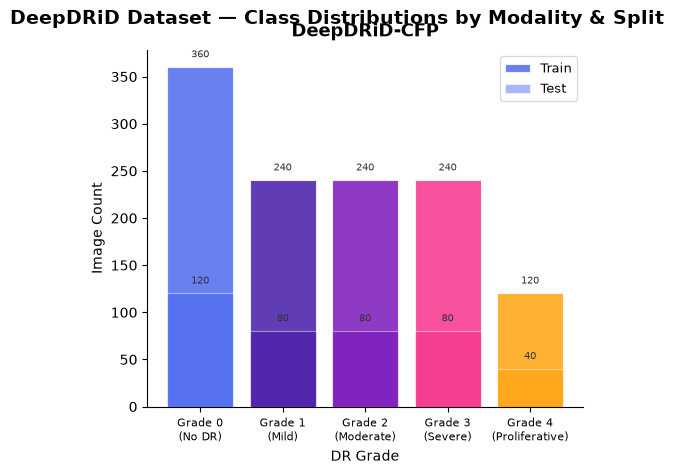

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures\dataset_distribution.pdf


In [14]:
def load_manifest(modality: str) -> pd.DataFrame | None:
    path = ROOT / 'data/DeepDRiD' / 'CFP_manifest.csv'
    if not path.exists():
        print(f'  [SKIP] manifest not found: {path}')
        return None
    return pd.read_csv(path)

manifests = {m: load_manifest(m) for m in MODALITIES}

# ── Plot class distributions ──────────────────────────────────────────────────
PALETTE = ['#4361EE', '#3A0CA3', '#7209B7', '#F72585', '#FF9E00',
           '#06D6A0', '#118AB2', '#EF233C']
GRADE_NAMES = ['Grade 0\n(No DR)', 'Grade 1\n(Mild)', 'Grade 2\n(Moderate)',
               'Grade 3\n(Severe)', 'Grade 4\n(Proliferative)']

available = {m: df for m, df in manifests.items() if df is not None}

if available:
    fig, axes = plt.subplots(1, len(available), figsize=(5 * len(available), 4.5),
                             constrained_layout=True)
    if len(available) == 1:
        axes = [axes]

    for ax, (mod, df) in zip(axes, available.items()):
        num_ranks = MODALITIES[mod]['num_ranks']
        for split, style in [('train', 0.8), ('test', 0.45)]:
            sub = df[df['split'] == split]
            counts = sub['grade'].value_counts().sort_index()
            bars = ax.bar(counts.index, counts.values,
                          color=[PALETTE[i] for i in counts.index],
                          alpha=style, edgecolor='white', linewidth=0.8,
                          label=split.capitalize())
            for bar in bars:
                h = bar.get_height()
                ax.text(bar.get_x() + bar.get_width() / 2, h + 8, f'{int(h):,}',
                        ha='center', va='bottom', fontsize=7, color='#333')

        ax.set_title(f'DeepDRiD-{mod}', fontsize=13, fontweight='bold', pad=10)
        ax.set_xlabel('DR Grade', fontsize=10)
        ax.set_ylabel('Image Count', fontsize=10)
        ax.set_xticks(range(num_ranks))
        ax.set_xticklabels(GRADE_NAMES[:num_ranks], fontsize=8)
        ax.legend(fontsize=9, framealpha=0.7)
        ax.spines[['top', 'right']].set_visible(False)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

    fig.suptitle('DeepDRiD Dataset — Class Distributions by Modality & Split',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.savefig(FIGURES / 'dataset_distribution.pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES / "dataset_distribution.pdf"}')
else:
    print('No manifests found. Run scripts/prepare_mmrdr.py first.')

## 4 · Prepare Few-Shot Splits

Generates support/query text files for each modality × k × seed combination.

In [15]:
SPLITS_DIR = ROOT / 'data/DeepDRiD' / 'splits'

def splits_exist(modality: str, k: int, seed: int) -> bool:
    mod_lower = modality.lower()
    sup = SPLITS_DIR / f'{mod_lower}_{k}shot_s{seed}_support.txt'
    qry = SPLITS_DIR / f'{mod_lower}_{k}shot_s{seed}_query.txt'
    return sup.exists() and qry.exists()

to_generate = [
    m for m in MODALITIES
    if manifests.get(m) is not None
    and not all(splits_exist(m, k, s) for k in fs_k for s in SEEDS)
]

if to_generate:
    print('Generating splits for:', to_generate)
    kshots_str = ','.join(str(k) for k in fs_k)
    seeds_str  = ','.join(str(s) for s in SEEDS)
    for mod in to_generate:
        cmd = [
            sys.executable, 'src/data/build_splits.py',
            '--modality', mod,
            '--dataset', 'DeepDRiD',
            '--kshots', kshots_str,
            '--seeds', seeds_str,
        ]
        result = subprocess.run(cmd, capture_output=True, text=True)
        print(result.stdout)
        if result.returncode != 0:
            print('ERROR:', result.stderr)
else:
    print('All splits already exist — skipping generation.')

All splits already exist — skipping generation.


## 5 · Training

### 5a · Single-run helper

This function trains (or skips if already done) one experiment and returns the test metrics.

In [16]:
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

def run_experiment(
    config_path: str,
    modality: str,
    k_shot: int,
    seed: int,
    variant_name: str = 'Ours (Full)',
    extra_overrides: dict | None = None,
    force_retrain: bool = False,
) -> dict:
    """
    Train and evaluate one experiment.
    Returns a dict of metrics, or loads cached results if they already exist.
    """
    import torch, omegaconf
    import numpy as np
    try:
        torch.serialization.add_safe_globals([
            np._core.multiarray.scalar, np.dtype, getattr(np.dtypes, 'Float64DType', None), getattr(np.dtypes, 'Int64DType', None),
            omegaconf.dictconfig.DictConfig, omegaconf.listconfig.ListConfig
        ])
    except Exception:
        pass

    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    stats_file = out_dir / 'test_stats.json'

    if stats_file.exists() and not force_retrain:
        with open(stats_file) as f:
            return json.load(f)

    out_dir.mkdir(parents=True, exist_ok=True)

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}', f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    pl.seed_everything(seed, workers=True)

    datamodule = FewShotDataModule(cfg)
    model = FewShotOrdinalRunner(cfg)

    monitor  = cfg.train.get('early_stopping_monitor', 'val_qwk')
    mode     = cfg.train.get('early_stopping_mode', 'max')
    patience = cfg.train.get('early_stopping_patience', 30)

    checkpoint_callback = ModelCheckpoint(
        dirpath=str(out_dir), filename='best',
        monitor=monitor, mode=mode, save_top_k=1, save_last=True
    )
    callbacks = [
        EarlyStopping(monitor=monitor, patience=patience, mode=mode, verbose=False),
        checkpoint_callback,
    ]

    try:
        prec = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '32-true'
    except Exception:
        prec = '32-true'

    trainer = pl.Trainer(
        max_epochs=EPOCHS if k_shot > 0 else 0,
        accelerator='auto', devices=1,
        precision=prec,
        gradient_clip_val=1.0,
        callbacks=callbacks,
        log_every_n_steps=1,
        enable_checkpointing=True,
        enable_progress_bar=True,
        logger=False,
        enable_model_summary=False,
    )

    if k_shot > 0:
        last_ckpt = out_dir / 'last.ckpt'
        if last_ckpt.exists():
            print(f'Resuming from {last_ckpt}')
            trainer.fit(model, datamodule=datamodule, ckpt_path=str(last_ckpt), weights_only=False)
        else:
            trainer.fit(model, datamodule=datamodule)
        
        # Test with the best checkpoint
        best_ckpt = checkpoint_callback.best_model_path
        if best_ckpt:
            model = FewShotOrdinalRunner.load_from_checkpoint(best_ckpt, cfg=cfg, weights_only=False)

    trainer.test(model, datamodule=datamodule, verbose=False)

    metrics = {k: float(v) for k, v in model.latest_metrics.items()}
    with open(stats_file, 'w') as f:
        json.dump(metrics, f, indent=4)

    return metrics

print('run_experiment() helper defined.')


run_experiment() helper defined.


### 5b · Run Full Experiment Grid (Main Model)

> **Tip**: Set `MODALITIES_TO_RUN` and `K_SHOTS_TO_RUN` to subset the grid for a quick test.

In [17]:
# ── Subset these to run only part of the grid ─────────────────────────────────
MODALITIES_TO_RUN = list(MODALITIES)      # e.g. ['CFP'] for a single modality
K_SHOTS_TO_RUN    = [0, 1, 2, 4, 8, 16, 32] #K_SHOTS               # e.g. [0, 4] for quick test
SEEDS_TO_RUN      = SEEDS

# ── Collect all results ───────────────────────────────────────────────────────
all_results = []  # list of dicts

total = len(MODALITIES_TO_RUN) * len(K_SHOTS_TO_RUN) * (
    1 if 0 in K_SHOTS_TO_RUN else 0  # zero-shot = 1 run per modality
) + len(MODALITIES_TO_RUN) * len([k for k in K_SHOTS_TO_RUN if k > 0]) * len(SEEDS_TO_RUN)

pbar = tqdm(total=total, desc='Experiments')

seen_zeroshot = set()  # zero-shot only once per modality

for mod in MODALITIES_TO_RUN:
    cfg_path = MODALITIES[mod]['config']

    for k in K_SHOTS_TO_RUN:
        seeds_for_k = [1] if k == 0 else SEEDS_TO_RUN  # zero-shot: single deterministic run

        for seed in seeds_for_k:
            if k == 0 and mod in seen_zeroshot:
                continue
            if k == 0:
                seen_zeroshot.add(mod)

            pbar.set_postfix({'mod': mod, 'k': k, 'seed': seed})

            metrics = run_experiment(
                config_path=cfg_path,
                modality=mod,
                k_shot=k,
                seed=seed,
                variant_name='Ours (Full)',
            )

            all_results.append({
                'Variant':  'Ours (Full)',
                'Modality': mod,
                'k':        k,
                'Seed':     seed,
                **metrics,
            })
            pbar.update(1)

pbar.close()

df_results = pd.DataFrame(all_results)
print('\nDone! Shape:', df_results.shape)
df_results.head(35)

Experiments:  84%|████████▍ | 31/37 [00:00<00:00, 325.54it/s, mod=CFP, k=32, seed=5]


Done! Shape: (31, 10)


,Variant,Modality,k,Seed,qwk,mae,f1,auc,acc,los
0,Ours (Full),CFP,0,1,0.066486,1.4250,0.136117,0.575198,0.2825,0.875
1,Ours (Full),CFP,1,1,0.310054,1.0525,0.229582,0.643646,0.2750,1.000
2,Ours (Full),CFP,1,2,0.380444,0.9775,0.267779,0.685101,0.3400,1.000
3,Ours (Full),CFP,1,3,0.089411,1.2050,0.089343,0.557917,0.1975,1.000
4,Ours (Full),CFP,1,4,0.052823,1.2050,0.090892,0.613958,0.2075,1.000
5,Ours (Full),CFP,1,5,0.379052,1.1425,0.197565,0.670592,0.3500,1.000
6,Ours (Full),CFP,2,1,0.346776,1.0025,0.250737,0.722972,0.2925,1.000
7,Ours (Full),CFP,2,2,0.478210,0.9125,0.326514,0.753244,0.3600,1.000
8,Ours (Full),CFP,2,3,0.412051,0.9900,0.309350,0.667111,0.3275,1.000
9,Ours (Full),CFP,2,4,0.427507,0.9825,0.225393,0.686867,0.2725,1.000


### 5c · Run Ablation Study

Runs CFP / k=4 / all seeds for each ablation variant. Skip if not needed.

In [18]:
RUN_ABLATIONS   = True    # set False to skip
ABLATION_MOD    = 'CFP'
ABLATION_K      = 16
ABLATION_SEEDS  = SEEDS

ablation_results = []

if RUN_ABLATIONS:
    cfg_path = MODALITIES[ABLATION_MOD]['config']
    total_abl = len(ABLATIONS) * len(ABLATION_SEEDS)
    pbar = tqdm(total=total_abl, desc='Ablations')

    for variant_name, overrides in ABLATIONS.items():
        for seed in ABLATION_SEEDS:
            pbar.set_postfix({'variant': variant_name, 'seed': seed})
            metrics = run_experiment(
                config_path=cfg_path,
                modality=ABLATION_MOD,
                k_shot=ABLATION_K,
                seed=seed,
                variant_name=variant_name,
                extra_overrides=overrides,
            )
            ablation_results.append({
                'Variant':  variant_name,
                'Modality': ABLATION_MOD,
                'k':        ABLATION_K,
                'Seed':     seed,
                **metrics,
            })
            pbar.update(1)
    pbar.close()

df_ablation = pd.DataFrame(ablation_results)
print('Ablation shape:', df_ablation.shape)
df_ablation.head()

Ablations:  33%|███▎      | 5/15 [00:00<00:00, 478.36it/s, variant=w/o SMS, seed=1]    Seed set to 1


Output()

Trainable parameters: 26494897


Trainable parameters: 26494897


Output()

...

Trainable parameters: 26494897


Output()

Ablations: 100%|██████████| 15/15 [10:12:36<00:00, 2450.40s/it, variant=w/o RankingLoss, seed=5]

Ablation shape: (15, 10)


,Variant,Modality,k,Seed,qwk,mae,f1,auc,acc,los
0,Ours (Full),CFP,16,1,0.705096,0.6325,0.483261,0.798567,0.5325,1.0
1,Ours (Full),CFP,16,2,0.723314,0.6100,0.464775,0.817678,0.4975,1.0
2,Ours (Full),CFP,16,3,0.670624,0.6775,0.461489,0.792480,0.4850,1.0
3,Ours (Full),CFP,16,4,0.778628,0.5350,0.505528,0.819597,0.5675,1.0
4,Ours (Full),CFP,16,5,0.758192,0.5400,0.516074,0.823022,0.5925,1.0


## 6 · Aggregate & Display Results Table

In [19]:
METRICS = ['qwk', 'mae', 'f1', 'auc', 'acc', 'los']
METRIC_LABELS = {'qwk': 'QWK↑', 'mae': 'MAE↓', 'f1': 'Macro-F1↑',
                 'auc': 'AUC↑', 'acc': 'Accuracy↑', 'los': 'LOS↑'}

def aggregate(df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    """Compute mean ± std per group."""
    rows = []
    for keys, grp in df.groupby(group_cols):
        row = dict(zip(group_cols, keys if isinstance(keys, tuple) else [keys]))
        for m in METRICS:
            if m in grp.columns:
                row[f'{m}_mean'] = grp[m].mean()
                row[f'{m}_std']  = grp[m].std(ddof=1) if len(grp) > 1 else 0.0
                row[m] = f"{grp[m].mean():.4f} ± {row[f'{m}_std']:.4f}"
        rows.append(row)
    return pd.DataFrame(rows)

# ── Main results table ────────────────────────────────────────────────────────
if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    display_cols = ['Variant', 'Modality', 'k'] + METRICS
    display(df_agg[display_cols].sort_values(['Modality', 'k']).to_string(index=False))

    # Save
    df_agg.to_csv(RESULTS / 'main_results.csv', index=False)
    print(f'\nSaved → {RESULTS / "main_results.csv"}')

'    Variant Modality  k             qwk             mae              f1             auc             acc             los\nOurs (Full)      CFP  0 0.0665 ± 0.0000 1.4250 ± 0.0000 0.1361 ± 0.0000 0.5752 ± 0.0000 0.2825 ± 0.0000 0.8750 ± 0.0000\nOurs (Full)      CFP  1 0.2424 ± 0.1594 1.1165 ± 0.0997 0.1750 ± 0.0814 0.6342 ± 0.0506 0.2740 ± 0.0714 1.0000 ± 0.0000\nOurs (Full)      CFP  2 0.3273 ± 0.2041 1.1355 ± 0.3675 0.2486 ± 0.0777 0.6747 ± 0.0806 0.2815 ± 0.0782 1.0000 ± 0.0000\nOurs (Full)      CFP  4 0.5542 ± 0.1664 0.8725 ± 0.2192 0.3259 ± 0.0964 0.7416 ± 0.0649 0.3815 ± 0.0958 1.0000 ± 0.0000\nOurs (Full)      CFP  8 0.6996 ± 0.0379 0.6615 ± 0.0470 0.4506 ± 0.0396 0.7935 ± 0.0208 0.5100 ± 0.0284 1.0000 ± 0.0000\nOurs (Full)      CFP 16 0.7272 ± 0.0427 0.5990 ± 0.0612 0.4862 ± 0.0242 0.8103 ± 0.0138 0.5350 ± 0.0455 1.0000 ± 0.0000\nOurs (Full)      CFP 32 0.7578 ± 0.0163 0.5685 ± 0.0409 0.5019 ± 0.0438 0.8263 ± 0.0095 0.5670 ± 0.0362 1.0000 ± 0.0000'


Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\main_results.csv


## 7 · Paper-Quality Plots

### 7a · k-Shot Performance Curves

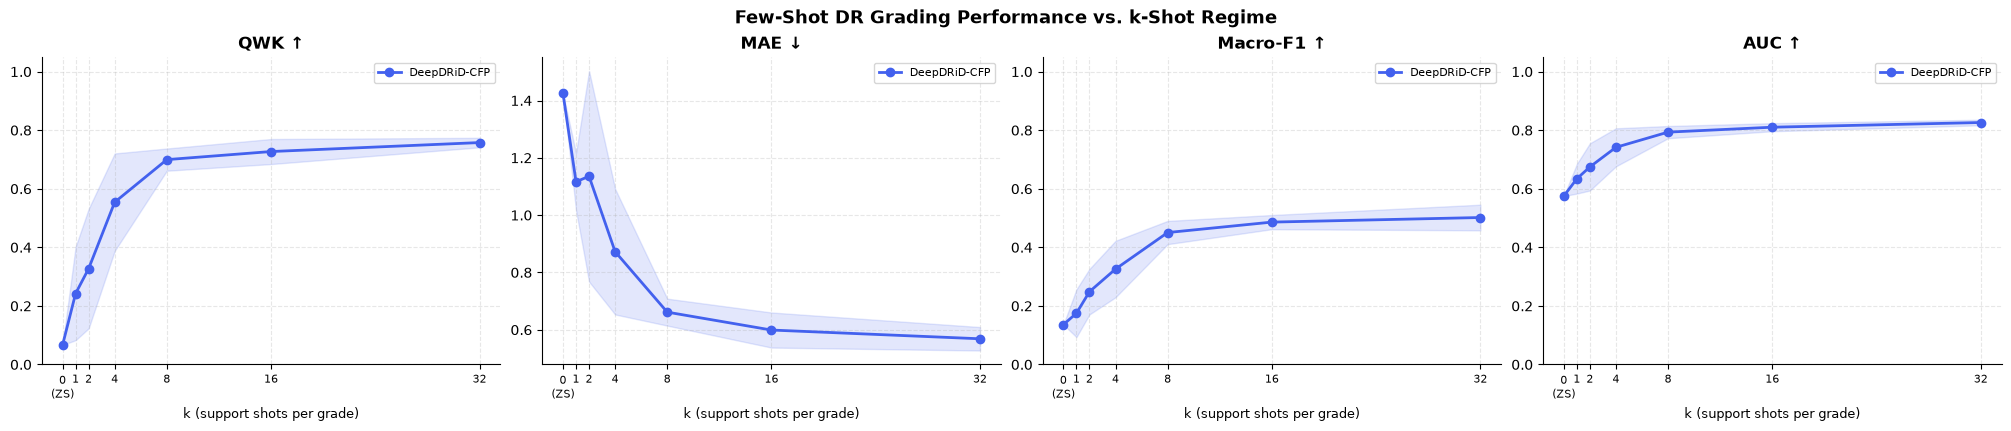

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures\kshot_curves.pdf


In [20]:
# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
})

MOD_COLORS  = {'CFP': '#4361EE', 'OCT': '#F72585', 'UWF': '#06D6A0'}
MOD_MARKERS = {'CFP': 'o',       'OCT': 's',       'UWF': '^'}

PLOT_METRICS = ['qwk', 'mae', 'f1', 'auc']
PLOT_LABELS  = ['QWK ↑', 'MAE ↓', 'Macro-F1 ↑', 'AUC ↑']

if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    main = df_agg[df_agg['Variant'] == 'Ours (Full)']

    fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(5 * len(PLOT_METRICS), 4.2),
                             constrained_layout=True)

    for ax, metric, label in zip(axes, PLOT_METRICS, PLOT_LABELS):
        for mod in MODALITIES_TO_RUN:
            sub = main[main['Modality'] == mod].sort_values('k')
            if sub.empty or f'{metric}_mean' not in sub.columns:
                continue
            mu  = sub[f'{metric}_mean'].values
            std = sub[f'{metric}_std'].values
            ks  = sub['k'].values

            ax.plot(ks, mu, marker=MOD_MARKERS[mod], color=MOD_COLORS[mod],
                    linewidth=2, markersize=6, label=f'DeepDRiD-{mod}')
            ax.fill_between(ks, mu - std, mu + std,
                            alpha=0.15, color=MOD_COLORS[mod])

        ax.set_title(label, fontsize=12, fontweight='bold')
        ax.set_xlabel('k (support shots per grade)', fontsize=9)
        ax.set_xticks(K_SHOTS_TO_RUN)
        ax.set_xticklabels([str(k) if k > 0 else '0\n(ZS)' for k in K_SHOTS_TO_RUN], fontsize=8)
        if metric in ('qwk', 'f1', 'auc', 'acc', 'los'):
            ax.set_ylim(0, 1.05)
        ax.legend(fontsize=8, framealpha=0.8)

    fig.suptitle('Few-Shot DR Grading Performance vs. k-Shot Regime',
                 fontsize=13, fontweight='bold')
    plt.savefig(FIGURES / 'kshot_curves.pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES / "kshot_curves.pdf"}')
else:
    print('No results yet — run Section 5 first.')

### 7b · Per-Modality Bar Chart (k = 4 and k = 16)

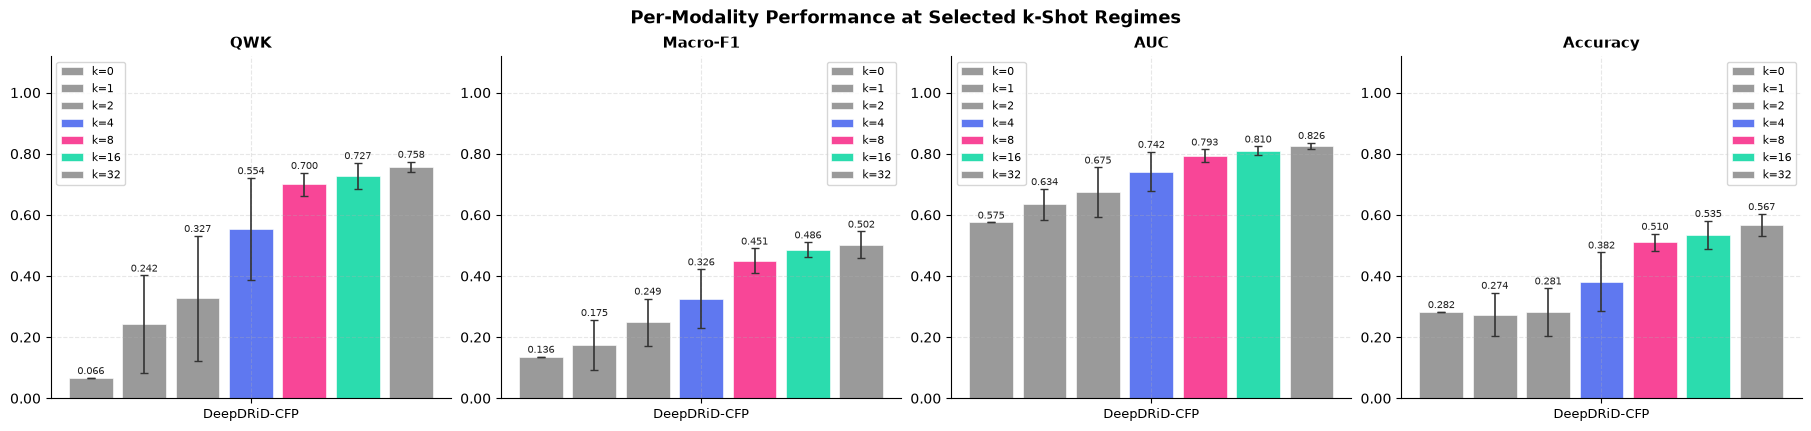

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures\modality_bar.pdf


In [21]:
BAR_K     = [0, 1, 2, 4, 8, 16, 32]
BAR_METS  = ['qwk', 'f1', 'auc', 'acc']
BAR_LABS  = ['QWK', 'Macro-F1', 'AUC', 'Accuracy']

if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    main = df_agg[(df_agg['Variant'] == 'Ours (Full)') & (df_agg['k'].isin(BAR_K))]

    n_mets = len(BAR_METS)
    n_k    = len(BAR_K)
    mods   = [m for m in MODALITIES_TO_RUN]
    x      = np.arange(len(mods))
    width  = 0.35 / n_k

    k_colors = {4: '#4361EE', 8: '#F72585', 16: '#06D6A0'}

    fig, axes = plt.subplots(1, n_mets, figsize=(4.5 * n_mets, 4.2),
                             constrained_layout=True)

    for ax, metric, label in zip(axes, BAR_METS, BAR_LABS):
        for i, k in enumerate(BAR_K):
            sub = main[main['k'] == k].set_index('Modality')
            vals = [sub.loc[m, f'{metric}_mean'] if m in sub.index else 0 for m in mods]
            errs = [sub.loc[m, f'{metric}_std']  if m in sub.index else 0 for m in mods]
            offset = (i - (n_k - 1) / 2) * width * 2.2
            bars = ax.bar(x + offset, vals, width * 1.8,
                          yerr=errs, capsize=3,
                          color=k_colors.get(k, '#888'),
                          alpha=0.85, label=f'k={k}',
                          edgecolor='white', linewidth=0.5,
                          error_kw={'elinewidth': 1.2, 'ecolor': '#333'})
            for bar, v in zip(bars, vals):
                ax.text(bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + max(errs) + 0.005,
                        f'{v:.3f}', ha='center', va='bottom',
                        fontsize=7, color='#222')

        ax.set_title(label, fontsize=11, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels([f'DeepDRiD-{m}' for m in mods], fontsize=9)
        ax.set_ylim(0, 1.12)
        ax.legend(fontsize=8, framealpha=0.8)
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

    fig.suptitle('Per-Modality Performance at Selected k-Shot Regimes',
                 fontsize=13, fontweight='bold')
    plt.savefig(FIGURES / 'modality_bar.pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES / "modality_bar.pdf"}')
else:
    print('No results yet.')

### 7c · Confusion Matrix (best seed, chosen modality & k)

Trainable parameters: 26494897


Output()

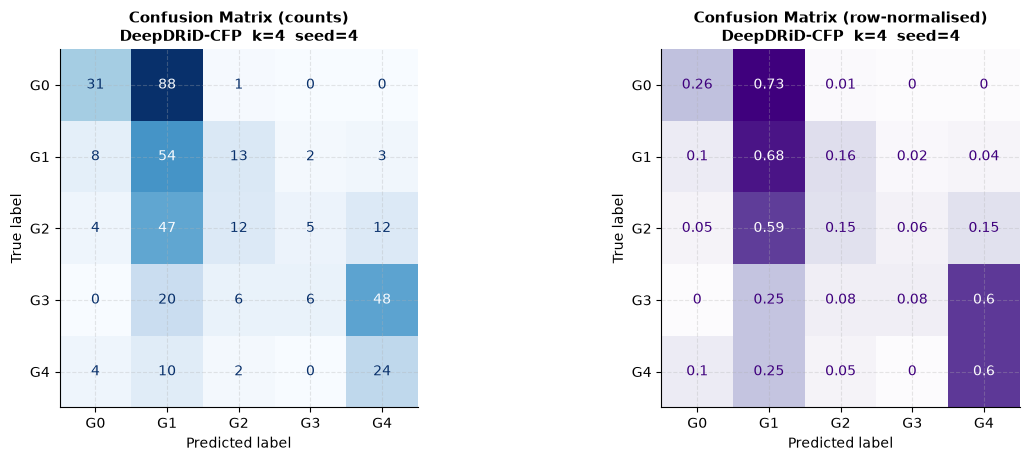

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures


In [22]:
CM_MOD   = 'CFP'
CM_K     = 4
CM_SEED  = 4

def get_predictions(config_path, modality, k_shot, seed, variant_name='Ours (Full)',
                    extra_overrides=None):
    """Re-run test pass and collect raw predictions for a confusion matrix."""
    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    ckpt    = out_dir / 'best.ckpt'

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}',
                 f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    datamodule = FewShotDataModule(cfg)

    if ckpt.exists():
        import torch, omegaconf
        try: torch.serialization.add_safe_globals([omegaconf.dictconfig.DictConfig])
        except: pass
        model = FewShotOrdinalRunner.load_from_checkpoint(str(ckpt), cfg=cfg, weights_only=False)
    else:
        model = FewShotOrdinalRunner(cfg)

    trainer = pl.Trainer(accelerator='auto', devices=1, precision='16-mixed',
                         logger=False, enable_progress_bar=True,
                         enable_model_summary=False)
    trainer.test(model, datamodule=datamodule, verbose=False)

    # val_preds/targets were cleared after test — collect from test step manually
    # They are in model.latest_metrics (scalars). For the CM we need raw outputs.
    # Re-collect by running predict loop:
    import torch.nn.functional as F
    datamodule.setup('test')
    loader = datamodule.test_dataloader()
    all_preds, all_targets = [], []
    model.eval().to(DEVICE)
    with torch.no_grad():
        for batch in loader:
            imgs, labels, _, _ = batch
            imgs = imgs.to(DEVICE)
            img_f, txt_f = model(imgs)
            scale = model.clip_model.logit_scale.exp()
            sim   = scale * img_f @ txt_f.T
            if model.sms is not None:
                sim = model.sms(sim)
            preds = F.softmax(sim, dim=-1).argmax(dim=-1).cpu()
            all_preds.append(preds)
            all_targets.append(labels)
    return torch.cat(all_targets).numpy(), torch.cat(all_preds).numpy()

if CM_MOD in MODALITIES_TO_RUN and CM_K in K_SHOTS_TO_RUN:
    cfg_path   = MODALITIES[CM_MOD]['config']
    num_ranks  = MODALITIES[CM_MOD]['num_ranks']

    targets, preds = get_predictions(cfg_path, CM_MOD, CM_K, CM_SEED)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

    # Raw count CM
    cm_counts = confusion_matrix(targets, preds)
    disp = ConfusionMatrixDisplay(cm_counts,
                                  display_labels=[f'G{i}' for i in range(num_ranks)])
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'Confusion Matrix (counts)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    # Row-normalised CM
    cm_norm = cm_counts.astype(float) / cm_counts.sum(axis=1, keepdims=True)
    disp2 = ConfusionMatrixDisplay(np.round(cm_norm, 2),
                                   display_labels=[f'G{i}' for i in range(num_ranks)])
    disp2.plot(ax=axes[1], cmap='Purples', colorbar=False)
    axes[1].set_title(f'Confusion Matrix (row-normalised)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    plt.savefig(FIGURES / f'confusion_{CM_MOD}_k{CM_K}_s{CM_SEED}.pdf',
                bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES}')
else:
    print(f'Skipping CM: {CM_MOD} k={CM_K} not in run grid.')

Output()

Trainable parameters: 26494897


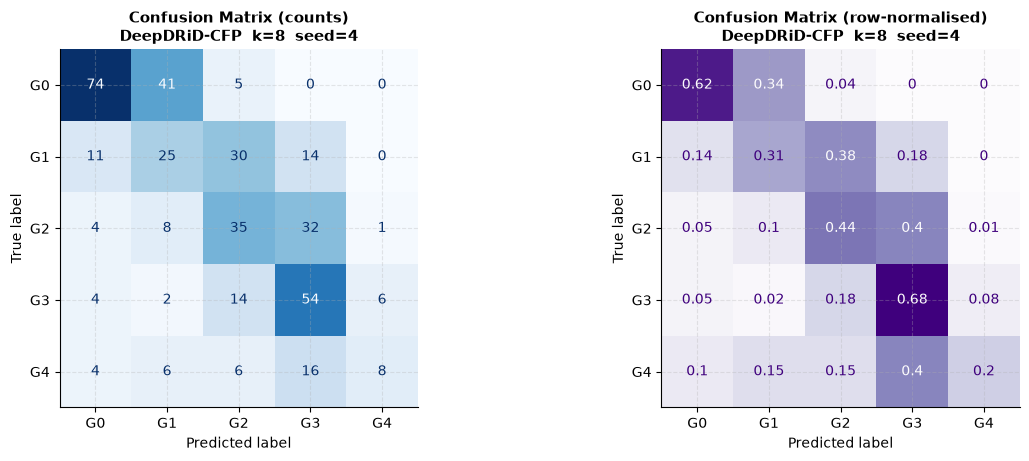

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures


In [23]:
CM_MOD   = 'CFP'
CM_K     = 8
CM_SEED  = 4

def get_predictions(config_path, modality, k_shot, seed, variant_name='Ours (Full)',
                    extra_overrides=None):
    """Re-run test pass and collect raw predictions for a confusion matrix."""
    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    ckpt    = out_dir / 'best.ckpt'

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}',
                 f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    datamodule = FewShotDataModule(cfg)

    if ckpt.exists():
        import torch, omegaconf
        try: torch.serialization.add_safe_globals([omegaconf.dictconfig.DictConfig])
        except: pass
        model = FewShotOrdinalRunner.load_from_checkpoint(str(ckpt), cfg=cfg, weights_only=False)
    else:
        model = FewShotOrdinalRunner(cfg)

    trainer = pl.Trainer(accelerator='auto', devices=1, precision='16-mixed',
                         logger=False, enable_progress_bar=True,
                         enable_model_summary=False)
    trainer.test(model, datamodule=datamodule, verbose=False)

    # val_preds/targets were cleared after test — collect from test step manually
    # They are in model.latest_metrics (scalars). For the CM we need raw outputs.
    # Re-collect by running predict loop:
    import torch.nn.functional as F
    datamodule.setup('test')
    loader = datamodule.test_dataloader()
    all_preds, all_targets = [], []
    model.eval().to(DEVICE)
    with torch.no_grad():
        for batch in loader:
            imgs, labels, _, _ = batch
            imgs = imgs.to(DEVICE)
            img_f, txt_f = model(imgs)
            scale = model.clip_model.logit_scale.exp()
            sim   = scale * img_f @ txt_f.T
            if model.sms is not None:
                sim = model.sms(sim)
            preds = F.softmax(sim, dim=-1).argmax(dim=-1).cpu()
            all_preds.append(preds)
            all_targets.append(labels)
    return torch.cat(all_targets).numpy(), torch.cat(all_preds).numpy()

if CM_MOD in MODALITIES_TO_RUN and CM_K in K_SHOTS_TO_RUN:
    cfg_path   = MODALITIES[CM_MOD]['config']
    num_ranks  = MODALITIES[CM_MOD]['num_ranks']

    targets, preds = get_predictions(cfg_path, CM_MOD, CM_K, CM_SEED)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

    # Raw count CM
    cm_counts = confusion_matrix(targets, preds)
    disp = ConfusionMatrixDisplay(cm_counts,
                                  display_labels=[f'G{i}' for i in range(num_ranks)])
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'Confusion Matrix (counts)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    # Row-normalised CM
    cm_norm = cm_counts.astype(float) / cm_counts.sum(axis=1, keepdims=True)
    disp2 = ConfusionMatrixDisplay(np.round(cm_norm, 2),
                                   display_labels=[f'G{i}' for i in range(num_ranks)])
    disp2.plot(ax=axes[1], cmap='Purples', colorbar=False)
    axes[1].set_title(f'Confusion Matrix (row-normalised)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    plt.savefig(FIGURES / f'confusion_{CM_MOD}_k{CM_K}_s{CM_SEED}.pdf',
                bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES}')
else:
    print(f'Skipping CM: {CM_MOD} k={CM_K} not in run grid.')

Output()

Trainable parameters: 26494897


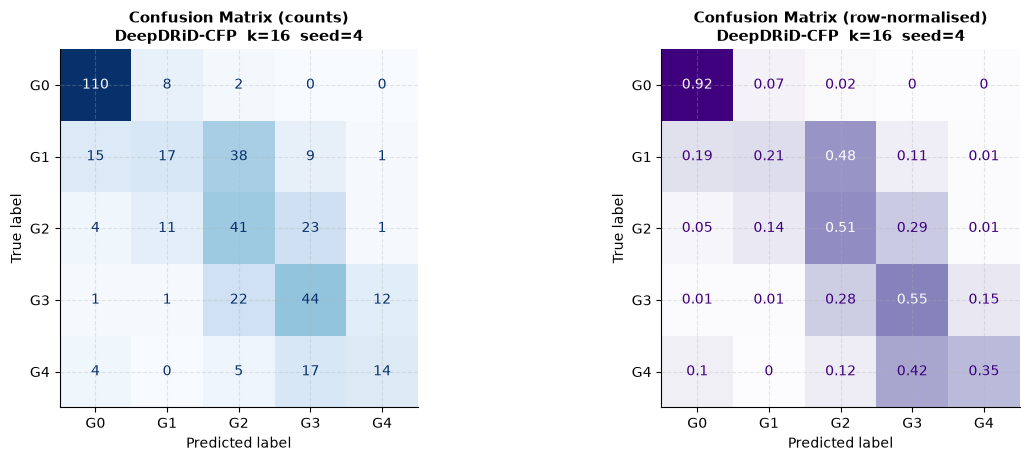

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures


In [24]:
CM_MOD   = 'CFP'
CM_K     = 16
CM_SEED  = 4

def get_predictions(config_path, modality, k_shot, seed, variant_name='Ours (Full)',
                    extra_overrides=None):
    """Re-run test pass and collect raw predictions for a confusion matrix."""
    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    ckpt    = out_dir / 'best.ckpt'

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}',
                 f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    datamodule = FewShotDataModule(cfg)

    if ckpt.exists():
        import torch, omegaconf
        try: torch.serialization.add_safe_globals([omegaconf.dictconfig.DictConfig])
        except: pass
        model = FewShotOrdinalRunner.load_from_checkpoint(str(ckpt), cfg=cfg, weights_only=False)
    else:
        model = FewShotOrdinalRunner(cfg)

    trainer = pl.Trainer(accelerator='auto', devices=1, precision='16-mixed',
                         logger=False, enable_progress_bar=True,
                         enable_model_summary=False)
    trainer.test(model, datamodule=datamodule, verbose=False)

    # val_preds/targets were cleared after test — collect from test step manually
    # They are in model.latest_metrics (scalars). For the CM we need raw outputs.
    # Re-collect by running predict loop:
    import torch.nn.functional as F
    datamodule.setup('test')
    loader = datamodule.test_dataloader()
    all_preds, all_targets = [], []
    model.eval().to(DEVICE)
    with torch.no_grad():
        for batch in loader:
            imgs, labels, _, _ = batch
            imgs = imgs.to(DEVICE)
            img_f, txt_f = model(imgs)
            scale = model.clip_model.logit_scale.exp()
            sim   = scale * img_f @ txt_f.T
            if model.sms is not None:
                sim = model.sms(sim)
            preds = F.softmax(sim, dim=-1).argmax(dim=-1).cpu()
            all_preds.append(preds)
            all_targets.append(labels)
    return torch.cat(all_targets).numpy(), torch.cat(all_preds).numpy()

if CM_MOD in MODALITIES_TO_RUN and CM_K in K_SHOTS_TO_RUN:
    cfg_path   = MODALITIES[CM_MOD]['config']
    num_ranks  = MODALITIES[CM_MOD]['num_ranks']

    targets, preds = get_predictions(cfg_path, CM_MOD, CM_K, CM_SEED)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

    # Raw count CM
    cm_counts = confusion_matrix(targets, preds)
    disp = ConfusionMatrixDisplay(cm_counts,
                                  display_labels=[f'G{i}' for i in range(num_ranks)])
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'Confusion Matrix (counts)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    # Row-normalised CM
    cm_norm = cm_counts.astype(float) / cm_counts.sum(axis=1, keepdims=True)
    disp2 = ConfusionMatrixDisplay(np.round(cm_norm, 2),
                                   display_labels=[f'G{i}' for i in range(num_ranks)])
    disp2.plot(ax=axes[1], cmap='Purples', colorbar=False)
    axes[1].set_title(f'Confusion Matrix (row-normalised)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    plt.savefig(FIGURES / f'confusion_{CM_MOD}_k{CM_K}_s{CM_SEED}.pdf',
                bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES}')
else:
    print(f'Skipping CM: {CM_MOD} k={CM_K} not in run grid.')

Output()

Trainable parameters: 26494897


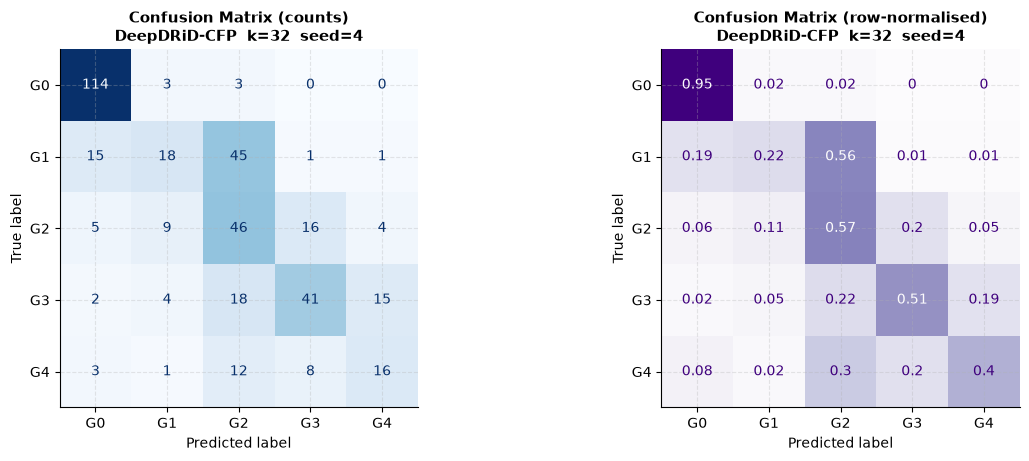

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures


In [25]:
CM_MOD   = 'CFP'
CM_K     = 32
CM_SEED  = 4

def get_predictions(config_path, modality, k_shot, seed, variant_name='Ours (Full)',
                    extra_overrides=None):
    """Re-run test pass and collect raw predictions for a confusion matrix."""
    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    ckpt    = out_dir / 'best.ckpt'

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}',
                 f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    datamodule = FewShotDataModule(cfg)

    if ckpt.exists():
        import torch, omegaconf
        try: torch.serialization.add_safe_globals([omegaconf.dictconfig.DictConfig])
        except: pass
        model = FewShotOrdinalRunner.load_from_checkpoint(str(ckpt), cfg=cfg, weights_only=False)
    else:
        model = FewShotOrdinalRunner(cfg)

    trainer = pl.Trainer(accelerator='auto', devices=1, precision='16-mixed',
                         logger=False, enable_progress_bar=True,
                         enable_model_summary=False)
    trainer.test(model, datamodule=datamodule, verbose=False)

    # val_preds/targets were cleared after test — collect from test step manually
    # They are in model.latest_metrics (scalars). For the CM we need raw outputs.
    # Re-collect by running predict loop:
    import torch.nn.functional as F
    datamodule.setup('test')
    loader = datamodule.test_dataloader()
    all_preds, all_targets = [], []
    model.eval().to(DEVICE)
    with torch.no_grad():
        for batch in loader:
            imgs, labels, _, _ = batch
            imgs = imgs.to(DEVICE)
            img_f, txt_f = model(imgs)
            scale = model.clip_model.logit_scale.exp()
            sim   = scale * img_f @ txt_f.T
            if model.sms is not None:
                sim = model.sms(sim)
            preds = F.softmax(sim, dim=-1).argmax(dim=-1).cpu()
            all_preds.append(preds)
            all_targets.append(labels)
    return torch.cat(all_targets).numpy(), torch.cat(all_preds).numpy()

if CM_MOD in MODALITIES_TO_RUN and CM_K in K_SHOTS_TO_RUN:
    cfg_path   = MODALITIES[CM_MOD]['config']
    num_ranks  = MODALITIES[CM_MOD]['num_ranks']

    targets, preds = get_predictions(cfg_path, CM_MOD, CM_K, CM_SEED)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

    # Raw count CM
    cm_counts = confusion_matrix(targets, preds)
    disp = ConfusionMatrixDisplay(cm_counts,
                                  display_labels=[f'G{i}' for i in range(num_ranks)])
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'Confusion Matrix (counts)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    # Row-normalised CM
    cm_norm = cm_counts.astype(float) / cm_counts.sum(axis=1, keepdims=True)
    disp2 = ConfusionMatrixDisplay(np.round(cm_norm, 2),
                                   display_labels=[f'G{i}' for i in range(num_ranks)])
    disp2.plot(ax=axes[1], cmap='Purples', colorbar=False)
    axes[1].set_title(f'Confusion Matrix (row-normalised)\nDeepDRiD-{CM_MOD}  k={CM_K}  seed={CM_SEED}',
                      fontsize=11, fontweight='bold')

    plt.savefig(FIGURES / f'confusion_{CM_MOD}_k{CM_K}_s{CM_SEED}.pdf',
                bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES}')
else:
    print(f'Skipping CM: {CM_MOD} k={CM_K} not in run grid.')

### 7d · Ablation Study Table & Plot

Ablation Study — DeepDRiD-CFP, k=4 shots (mean ± std over 5 seeds)


,Variant,qwk,mae,f1,auc,acc,los
0,Ours (Full),0.7272 ± 0.0427,0.5990 ± 0.0612,0.4862 ± 0.0242,0.8103 ± 0.0138,0.5350 ± 0.0455,1.0000 ± 0.0000
1,w/o RankingLoss,0.7000 ± 0.0215,0.6360 ± 0.0099,0.4863 ± 0.0282,0.8104 ± 0.0165,0.5490 ± 0.0174,1.0000 ± 0.0000
2,w/o SMS,0.7408 ± 0.0279,0.5780 ± 0.0230,0.5118 ± 0.0165,0.8276 ± 0.0037,0.5685 ± 0.0151,0.9765 ± 0.0127


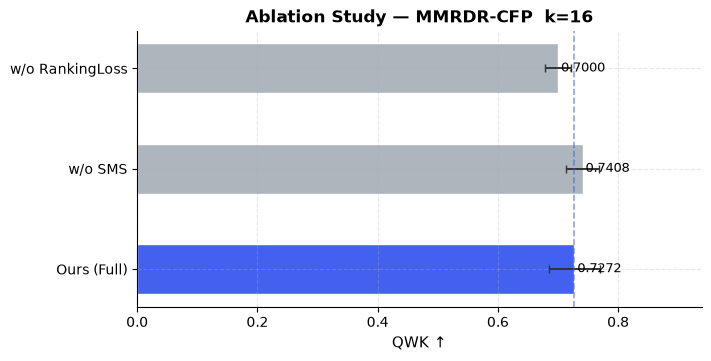

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures\ablation_qwk.pdf


In [26]:
if not df_ablation.empty:
    df_abl_agg = aggregate(df_ablation, ['Variant', 'Modality', 'k'])

    # ── Nicely formatted table ────────────────────────────────────────────
    display_cols = ['Variant'] + METRICS
    print('Ablation Study — DeepDRiD-CFP, k=4 shots (mean ± std over 5 seeds)')
    print('=' * 80)
    display(df_abl_agg[display_cols])
    df_abl_agg[display_cols].to_csv(RESULTS / 'ablation_results.csv', index=False)

    # ── Horizontal bar chart: QWK ─────────────────────────────────────────
    abl_mods = list(ABLATIONS.keys())
    full_idx  = abl_mods.index('Ours (Full)')
    qwk_vals  = []
    qwk_errs  = []
    for v in abl_mods:
        row = df_abl_agg[df_abl_agg['Variant'] == v]
        if row.empty or 'qwk_mean' not in row.columns:
            qwk_vals.append(0); qwk_errs.append(0)
        else:
            qwk_vals.append(row['qwk_mean'].values[0])
            qwk_errs.append(row['qwk_std'].values[0])

    colors = ['#4361EE' if i == full_idx else '#ADB5BD' for i in range(len(abl_mods))]
    y_pos  = np.arange(len(abl_mods))

    fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
    bars = ax.barh(y_pos, qwk_vals, xerr=qwk_errs, height=0.5,
                   color=colors, edgecolor='white', capsize=3,
                   error_kw={'elinewidth': 1.4, 'ecolor': '#333'})
    for bar, v in zip(bars, qwk_vals):
        ax.text(v + 0.005, bar.get_y() + bar.get_height() / 2,
                f'{v:.4f}', va='center', fontsize=9)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(abl_mods, fontsize=10)
    ax.set_xlabel('QWK ↑', fontsize=11)
    ax.set_title(f'Ablation Study — MMRDR-{ABLATION_MOD}  k={ABLATION_K}',
                 fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(qwk_vals) * 1.2 + 0.05)
    ax.axvline(qwk_vals[full_idx], color='#4361EE', linestyle='--',
               linewidth=1.2, alpha=0.6)

    plt.savefig(FIGURES / 'ablation_qwk.pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES / "ablation_qwk.pdf"}')
else:
    print('No ablation results yet — run Section 5c first.')

### 7e · Radar / Spider Chart — Per-Metric Overview at k=16

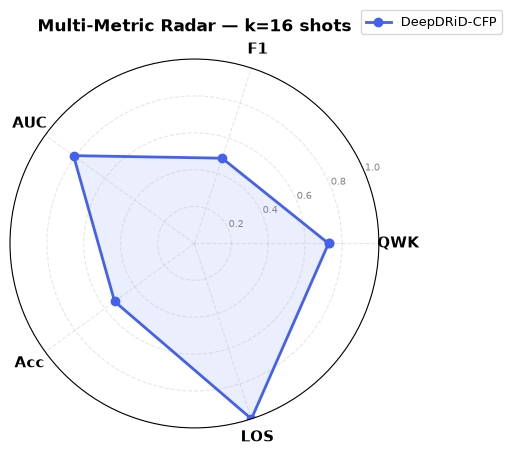

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\results\figures\radar_k16.pdf


In [27]:
RADAR_K = 16
RADAR_METRICS = ['qwk', 'f1', 'auc', 'acc', 'los']
RADAR_LABELS  = ['QWK', 'F1', 'AUC', 'Acc', 'LOS']

if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    radar_data = df_agg[(df_agg['Variant'] == 'Ours (Full)') & (df_agg['k'] == RADAR_K)]

    if radar_data.empty:
        print(f'No data at k={RADAR_K}; adjust RADAR_K.')
    else:
        N = len(RADAR_METRICS)
        angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
        angles += angles[:1]  # close polygon

        fig, ax = plt.subplots(figsize=(5, 5),
                               subplot_kw={'projection': 'polar'},
                               constrained_layout=True)

        for mod in MODALITIES_TO_RUN:
            row = radar_data[radar_data['Modality'] == mod]
            if row.empty:
                continue
            vals = [row[f'{m}_mean'].values[0] for m in RADAR_METRICS]
            vals += vals[:1]
            ax.plot(angles, vals, color=MOD_COLORS[mod], linewidth=2,
                    marker=MOD_MARKERS[mod], markersize=6, label=f'DeepDRiD-{mod}')
            ax.fill(angles, vals, color=MOD_COLORS[mod], alpha=0.1)

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(RADAR_LABELS, fontsize=11, fontweight='bold')
        ax.set_ylim(0, 1)
        ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
        ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=7, color='#888')
        ax.set_title(f'Multi-Metric Radar — k={RADAR_K} shots',
                     fontsize=12, fontweight='bold', pad=20)
        ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=9)

        plt.savefig(FIGURES / f'radar_k{RADAR_K}.pdf', bbox_inches='tight', dpi=300)
        plt.show()
        print(f'Saved → {FIGURES / f"radar_k{RADAR_K}.pdf"}')
else:
    print('No results yet.')

### 7f · Training Dynamics (Loss & Validation QWK vs. Epoch)

For this plot, enable Lightning CSV logging during training by setting `logger=True` in `run_experiment()` and then reading the `metrics.csv` file.

In [28]:
# Reads Lightning's default CSV logger output if available
DYNAMICS_MOD  = 'CFP'
DYNAMICS_K    = 16
DYNAMICS_SEED = 4
VARIANT_SLUG  = 'Ours_Full_'

lightning_logs = ROOT / 'lightning_logs'

if lightning_logs.exists():
    versions = sorted(lightning_logs.glob('version_*/metrics.csv'))
    if versions:
        # Use the most recent version (last run)
        df_log = pd.read_csv(versions[-1])
        print(f'Loaded: {versions[-1]}')
        print(df_log.columns.tolist())

        fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)

        for col, ax, label in [
            ('train_loss', axes[0], 'Training Loss'),
            ('val_qwk',   axes[1], 'Validation QWK'),
        ]:
            if col in df_log.columns:
                sub = df_log[['epoch', col]].dropna()
                ax.plot(sub['epoch'], sub[col], color='#4361EE', linewidth=2)
                ax.set_xlabel('Epoch', fontsize=10)
                ax.set_title(label, fontsize=11, fontweight='bold')
                ax.spines[['top', 'right']].set_visible(False)

        fig.suptitle(f'Training Dynamics — MMRDR-{DYNAMICS_MOD}  k={DYNAMICS_K}  seed={DYNAMICS_SEED}',
                     fontsize=12, fontweight='bold')
        plt.savefig(FIGURES / 'training_dynamics.pdf', bbox_inches='tight', dpi=300)
        plt.show()
    else:
        print('No metrics.csv found in lightning_logs. Enable CSV logger to generate.')
else:
    print('lightning_logs/ not found. Skip this plot or enable CSV logging in run_experiment().')

lightning_logs/ not found. Skip this plot or enable CSV logging in run_experiment().


## 8 · Final Summary Table (LaTeX-ready)

Generates a LaTeX table for direct copy-paste into the paper.

In [29]:
if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    main = df_agg[df_agg['Variant'] == 'Ours (Full)'].sort_values(['Modality', 'k'])

    # ── Build LaTeX rows ──────────────────────────────────────────────────
    print('% ─── LaTeX Table ───────────────────────────────────────────────')
    print(r'\begin{table}[ht]')
    print(r'\centering')
    print(r'\caption{Few-Shot DR Grading on MMRDR (mean $\pm$ std over 5 seeds)}')
    print(r'\label{tab:main}')
    print(r'\begin{tabular}{llrcccc}')
    print(r'\toprule')
    print(r'Modality & k & QWK $\uparrow$ & MAE $\downarrow$ & F1 $\uparrow$ & AUC $\uparrow$ \\')
    print(r'\midrule')

    prev_mod = None
    for _, row in main.iterrows():
        mod_str = f'MMRDR-{row["Modality"]}' if row['Modality'] != prev_mod else ''
        prev_mod = row['Modality']
        k_str = 'ZS' if row['k'] == 0 else str(int(row['k']))
        qwk  = f"{row.get('qwk_mean', 0):.3f}$\\pm${row.get('qwk_std', 0):.3f}"
        mae  = f"{row.get('mae_mean', 0):.3f}$\\pm${row.get('mae_std', 0):.3f}"
        f1   = f"{row.get('f1_mean',  0):.3f}$\\pm${row.get('f1_std',  0):.3f}"
        auc  = f"{row.get('auc_mean', 0):.3f}$\\pm${row.get('auc_std', 0):.3f}"
        print(f'{mod_str} & {k_str} & {qwk} & {mae} & {f1} & {auc} \\\\')
    print(r'\bottomrule')
    print(r'\end{tabular}')
    print(r'\end{table}')
    print('% ────────────────────────────────────────────────────────────────')
else:
    print('No results yet — run Section 5b first.')

% ─── LaTeX Table ───────────────────────────────────────────────
\begin{table}[ht]
\centering
\caption{Few-Shot DR Grading on MMRDR (mean $\pm$ std over 5 seeds)}
\label{tab:main}
\begin{tabular}{llrcccc}
\toprule
Modality & k & QWK $\uparrow$ & MAE $\downarrow$ & F1 $\uparrow$ & AUC $\uparrow$ \\
\midrule
MMRDR-CFP & ZS & 0.066$\pm$0.000 & 1.425$\pm$0.000 & 0.136$\pm$0.000 & 0.575$\pm$0.000 \\
 & 1 & 0.242$\pm$0.159 & 1.117$\pm$0.100 & 0.175$\pm$0.081 & 0.634$\pm$0.051 \\
 & 2 & 0.327$\pm$0.204 & 1.135$\pm$0.368 & 0.249$\pm$0.078 & 0.675$\pm$0.081 \\
 & 4 & 0.554$\pm$0.166 & 0.872$\pm$0.219 & 0.326$\pm$0.096 & 0.742$\pm$0.065 \\
 & 8 & 0.700$\pm$0.038 & 0.661$\pm$0.047 & 0.451$\pm$0.040 & 0.793$\pm$0.021 \\
 & 16 & 0.727$\pm$0.043 & 0.599$\pm$0.061 & 0.486$\pm$0.024 & 0.810$\pm$0.014 \\
 & 32 & 0.758$\pm$0.016 & 0.569$\pm$0.041 & 0.502$\pm$0.044 & 0.826$\pm$0.009 \\
\bottomrule
\end{tabular}
\end{table}
% ────────────────────────────────────────────────────────────────


## 9 · Quick Sanity Check (single forward pass)

Useful to confirm the model loads and runs before committing to a full sweep.

In [30]:
import torch.nn.functional as F

SANITY_MOD = 'CFP'
SANITY_K   = 4

cfg_path = MODALITIES[SANITY_MOD]['config']
cfg = load_config(cfg_path, [f'data.k_shot={SANITY_K}', 'data.seed=1'])

model = FewShotOrdinalRunner(cfg).to(DEVICE)
model.eval()

dummy = torch.randn(4, 3, 224, 224).to(DEVICE)
with torch.no_grad():
    img_f, txt_f = model(dummy)
    scale = model.clip_model.logit_scale.exp()
    sim   = scale * img_f @ txt_f.T
    probs = F.softmax(sim, dim=-1)
    preds = probs.argmax(dim=-1)

print(f'Image features shape : {img_f.shape}')
print(f'Text  features shape : {txt_f.shape}')
print(f'Similarity matrix    : {sim.shape}')
print(f'Probabilities        : {probs.round(decimals=4)}')
print(f'Predictions          : {preds.tolist()}')
print('\n✅ Sanity check passed!')

Trainable parameters: 26494897
Image features shape : torch.Size([4, 1024])
Text  features shape : torch.Size([5, 1024])
Similarity matrix    : torch.Size([4, 5])
Probabilities        : tensor([[0.1010, 0.1700, 0.2576, 0.3297, 0.1417],
        [0.0981, 0.1680, 0.2486, 0.3417, 0.1436],
        [0.0994, 0.1666, 0.2481, 0.3384, 0.1475],
        [0.1021, 0.1646, 0.2427, 0.3363, 0.1543]], device='cuda:0')
Predictions          : [3, 3, 3, 3]

✅ Sanity check passed!
